# CA-Transformer Quick Start

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sdean-group/ICL-CA/blob/main/quickstart.ipynb)

Small transformers that infer a **cellular-automaton rule in context**. Each model sees the first $M$ frames of a trajectory generated by a rule it has *never seen during training*, then predicts the rest.

There are 12 released models ([Hugging Face collection](https://huggingface.co/collections/sdeangroup/spatial-induction-heads)):
3 tasks (1D $V{=}2$, 1D $V{=}3$, 2D von Neumann) × deterministic / stochastic rules × *Shared* / *Dedicated* architecture.

This notebook downloads **one** checkpoint (a few MB to ~50 MB) and runs in a few minutes on a CPU.
It covers six steps: install, load a model, generate an example, run inference, visualize, and try your own rule and context.

## 1. Install

On Colab this cell clones the repository and installs it (a CPU runtime is enough). Locally, run the notebook from the root of your clone.

In [1]:
import os, sys

if "google.colab" in sys.modules and not os.path.exists("configs/pretrained_models.yaml"):
    if not os.path.exists("ICL-CA"):
        !git clone -q https://github.com/sdean-group/ICL-CA.git
    %cd ICL-CA

%pip install -q -e .

# Make `src` importable right away (Colab does not put the working directory on
# sys.path, and a fresh editable install is only picked up after a restart).
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

Note: you may need to restart the kernel to use updated packages.


## 2. Pick and load a model

`list_pretrained()` shows every released model. To try a different one, change `MODEL` and re-run the notebook.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from src import (list_pretrained, load_pretrained, generate_example, generate_examples,
                 predict, rollout, evaluate, continue_trajectory, check_context,
                            plot_example, plot_prediction, plot_rollout, plot_ar_accuracy)

list_pretrained()

key,task,grid,T,M,architecture,d_model
1d-det-v2k3-shared,1D det V=2 K=3,16,10,4,shared,128
1d-det-v2k3-dedicated,1D det V=2 K=3,16,10,4,dedicated,128
1d-det-v3k3-shared,1D det V=3 K=3,32,12,8,shared,256
1d-det-v3k3-dedicated,1D det V=3 K=3,32,12,8,dedicated,256
2d-det-v2k5-shared,2D det V=2 K=5,6x6,12,8,shared,1024
2d-det-v2k5-dedicated,2D det V=2 K=5,6x6,12,8,dedicated,1024
1d-stoch-v2k3-shared,1D stoch V=2 K=3,16,20,10,shared,256
1d-stoch-v2k3-dedicated,1D stoch V=2 K=3,16,20,10,dedicated,128
1d-stoch-v3k3-shared,1D stoch V=3 K=3,16,20,10,shared,256
1d-stoch-v3k3-dedicated,1D stoch V=3 K=3,16,20,10,dedicated,256


In [3]:
MODEL = "1d-det-v2k3-shared"     # <- change me

bundle = load_pretrained(MODEL, device="auto")   # downloads only this checkpoint (cached afterwards)
bundle

/share/dean/mx253/envs/eca/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ModelBundle(1d-det-v2k3-shared: 1D det V=2 K=3, grid 16, T=10, M=4, shared (d_model=128, heads=[1, 1]); 0.42M params; device=cpu)

`bundle.spec` holds everything about the task and architecture: the grid shape, the number of frames $T$, the context length $M$, the separator token ids, and so on.

In [15]:
bundle.spec

ModelSpec(key='1d-det-v2k3-shared', repo_id='sdeangroup/CA-Transformer-1D-Det-V2K3-Shared', dimension=1, stochastic=False, V=2, K=3, grid_shape=(16,), T=10, M=4, neighborhood='elementary', architecture='shared', d_model=128, heads=(1, 1), mlp=(1, 1), time_sep=2, row_sep=None, rule_pool='1d_v2k3', train_data='V2K3_ECA_L16_T10_M4_wolfram70-9-9can_n50M_test500k_seed42')

## 3. Generate an example

By default the rule is drawn from the **held-out test pool**, meaning rules the model never trained on. For stochastic models it is a fresh random transition table. As in the test set, the initial state is resampled until every neighborhood configuration appears in the context, so the rule is fully identifiable.

rule: 209 | split: heldout_test
context: (4, 16)  full trajectory: (10, 16)


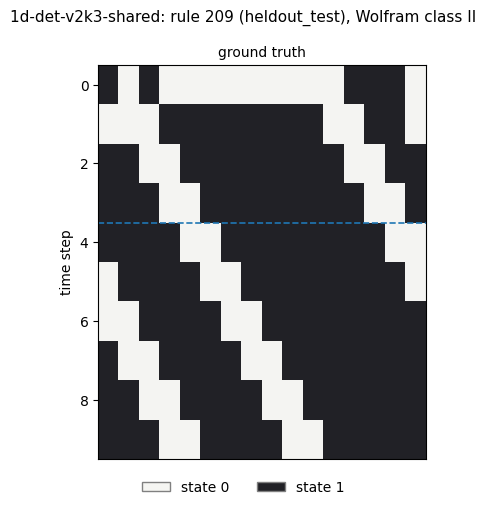

In [5]:
example = generate_example(bundle.spec, seed=0)
print("rule:", example.rule if not bundle.spec.stochastic else f"{example.rule.shape} transition table",
      "| split:", example.rule_split)
print("context:", example.context.shape, " full trajectory:", example.trajectory.shape)
plot_example(example);

You can also pick the rule yourself:
* **deterministic:** an integer (the Wolfram number for 1D $V{=}2$, e.g. `rule=110`) or a full output table of shape `(V**K,)`;
* **stochastic:** an array of shape `(V**K, V)` whose row $i$ is the next-state distribution for neighborhood configuration $i$.

In [6]:
if bundle.spec.key.startswith("1d-det-v2k3"):
    example = generate_example(bundle.spec, rule=110, seed=0)   # rule 110 is held out: never seen in training
    print("rule 110 split:", example.rule_split)

rule 110 split: heldout_test


## 4. Run inference

`predict` runs both evaluation modes:
* **teacher-forced:** a single forward pass over the ground-truth sequence; each cell is predicted from the true history;
* **autoregressive:** the model sees only the first $M$ frames and generates the rest itself (greedy for deterministic models, sampled for stochastic ones).

Metrics are computed on frames $M..T-1$. Deterministic models report cell and sequence accuracy. Stochastic models report $\mathrm{KL}(\text{reference} \,\|\, \text{model})$ against the true rule and against the causal add-one $k$-gram estimate from the context. These are the same definitions as the paper's evaluator.

In [7]:
result = predict(bundle, example, mode="both")
result.metrics

{'tf/cell_acc': 1.0,
 'tf/seq_acc': 1.0,
 'ar/cell_acc': 1.0,
 'ar/seq_acc': 1.0,
 'ar/cell_acc_by_step': {4: 1.0, 5: 1.0, 6: 1.0, 7: 1.0, 8: 1.0, 9: 1.0},
 'n_trajectories': 1}

## 5. Visualize

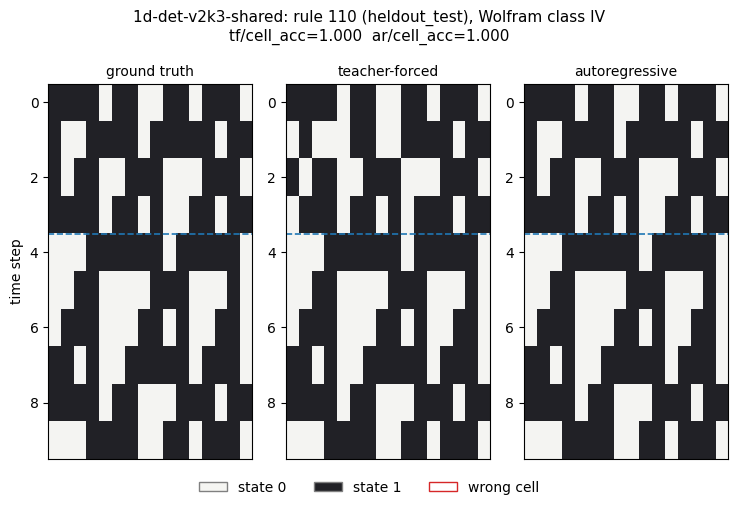

In [8]:
plot_prediction(example, result);

How to read the plot:
* **1D:** time runs downward and the dashed line marks the end of the context.
* **2D:** frames with blue borders are context.
* **Deterministic models:** red boxes are wrong cells.
* **Stochastic models:** colors are probability-weighted mixes of the state colors, so for $V{=}2$ the shade is $P(\text{state}=1)$.

To get a more reliable number, score a batch of fresh held-out examples. For the full evaluation (100k fresh test trajectories, teacher-forced + autoregressive), run `python -m src.evaluate --model <key>`.

In [9]:
batch = generate_examples(bundle.spec, n=64, seed=1)
batch_result = predict(bundle, batch)
{k: v for k, v in batch_result.metrics.items() if k != "ar/cell_acc_by_step"}

{'tf/cell_acc': 1.0,
 'tf/seq_acc': 1.0,
 'ar/cell_acc': 1.0,
 'ar/seq_acc': 1.0,
 'n_trajectories': 64}

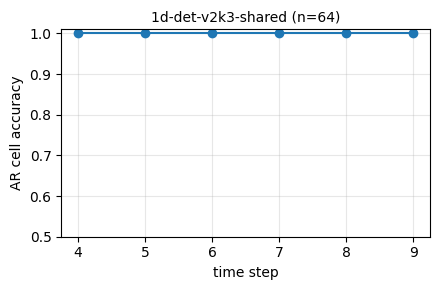

In [10]:
if not bundle.spec.stochastic:
    plot_ar_accuracy(batch_result);

## 6. Try your own rule and context

Give the model your own input:
* `RULE` is the rule that generates the trajectory. For deterministic models it is a rule number (the Wolfram number for 1D $V{=}2$) or a `(V**K,)` output table. For stochastic models it is a `(V**K, V)` array of next-state probabilities.
* `CONTEXT` is the frames the model sees, shape `(m, *grid)` with states in `0..V-1`. Each frame must follow from the previous one under `RULE`. The models were trained with $m = M$.

The model only sees `CONTEXT`. `RULE` gives the ground truth: `continue_trajectory` simulates it forward from the last context frame, and the model's rollout is scored against that.

The defaults below are for the 1D $V{=}2$ deterministic models: rule 110 (held out from training) with a 4-frame context of 16 cells. For other models the cell falls back to a held-out rule and a simulated context.

In [11]:
spec = bundle.spec

# ---- your inputs ------------------------------------------------------------
RULE = 110
CONTEXT = np.array([
    [1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0],
    [1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1],
    [1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0],
    [1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1],
])
# -----------------------------------------------------------------------------

if not spec.key.startswith("1d-det-v2k3"):      # defaults above don't fit this model
    ex = generate_example(spec, seed=7)          # held-out rule (random table if stochastic)
    RULE, CONTEXT = ex.rule, ex.trajectory[: spec.M]

check_context(spec, CONTEXT, RULE)

{'follows_rule': True, 'violations': 0, 'configs_seen': 8, 'num_configs': 8}

`check_context` reports whether every transition in `CONTEXT` is possible under `RULE` (`follows_rule`) and how many of the $V^K$ neighborhood configurations appear in it (`configs_seen`). Rule entries whose configuration never appears cannot be inferred from the context; the test set requires all of them.

{'cell_acc_vs_reference': 1.0}


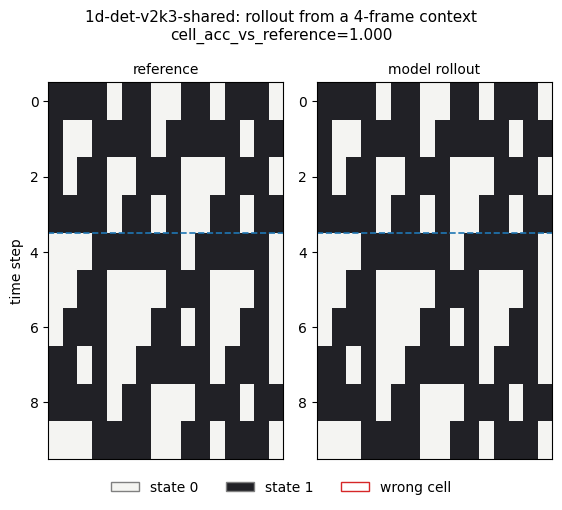

In [12]:
reference = continue_trajectory(spec, CONTEXT, RULE, num_frames=spec.T - len(CONTEXT), seed=0)
result = rollout(bundle, CONTEXT, reference=reference)
print(result.metrics)
plot_rollout(result);

Without a rule there is no ground truth, but the model still continues the context: `plot_rollout(rollout(bundle, CONTEXT))`. For stochastic rules, `continue_trajectory` gives one random realization per `seed`, and stochastic rollouts are sampled.

## Next steps
* Set `MODEL` to a 2D or stochastic model, e.g. `"2d-det-v2k5-dedicated"` or `"1d-stoch-v3k3-shared"`, and re-run the notebook.
* `evaluate(bundle, n=512)` gives a quick estimate of the paper metrics.
* The arrays behind every plot are on the result objects: `result.tf_probs`, `result.ar_states`, `result.ar_probs`.